### A) CODE (MAIN IMPLEMENTATION)

In [1]:
# Install tshark (command-line Wireshark) quietly
!DEBIAN_FRONTEND=noninteractive apt-get install -y -qq tshark > /dev/null

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

import os, glob
from collections import Counter

DATASET = '/content/drive/MyDrive/Computer_Security_Project/dataset'

# Find every capture file in all subfolders
pcaps = sorted(glob.glob(f'{DATASET}/**/*.pcap*', recursive=True))

def label_of(path):
    """Derive the class label from the folder name, e.g. 'youtube_data2' -> 'Youtube'."""
    folder = os.path.basename(os.path.dirname(path))
    return folder.split('_')[0].capitalize()

print(len(pcaps), "pcap files found")
print(Counter(label_of(p) for p in pcaps))

Mounted at /content/drive
74 pcap files found
Counter({'Wikipedia': 20, 'Youtube': 20, 'Discord': 14, 'Soundcloud': 10, 'Spotify': 10})


we will keep going on this discord example in the following parts..

In [17]:
import subprocess
import numpy as np

def read_packets(pcap_path):

    """
    Returns three arrays, one entry per IP packet:
      times      - timestamp in seconds
      sizes      - packet length in bytes
      directions - +1 if sent by the user (outgoing), -1 if received (incoming)
    """

    cmd = ['tshark', '-r', pcap_path, '-T', 'fields', # telling tshark -r read, -E do, -e write
           '-E', 'separator=\t', '-E', 'occurrence=f',
           '-e', 'frame.time_epoch', '-e', 'frame.len',
           '-e', 'ip.src', '-e', 'ipv6.src', '-e', 'ip.dst', '-e', 'ipv6.dst']
    output = subprocess.run(cmd, capture_output=True, text=True).stdout

    times, sizes, srcs, dsts = [], [], [], []
    for line in output.splitlines():
        t, size, src4, src6, dst4, dst6 = line.split('\t')
        src, dst = src4 or src6, dst4 or dst6 # IPv4 or IPv6
        if not src or not dst:
            continue # skip non-IP packets
        times.append(float(t))
        sizes.append(int(size))
        srcs.append(src)
        dsts.append(dst)

    # The user's own machine is the address that appears in the most packets
    client = Counter(srcs + dsts).most_common(1)[0][0]
    directions = [1 if s == client else -1 for s in srcs]

    # Sort everything by time
    order = np.argsort(times)
    return (np.array(times)[order],
            np.array(sizes)[order],
            np.array(directions)[order])

In [8]:
def stats(prefix, values):

    """Summarise a list of numbers with mean, standard deviation and maximum."""

    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return {f'{prefix}_mean': 0.0, f'{prefix}_std': 0.0, f'{prefix}_max': 0.0}
    return {f'{prefix}_mean': values.mean(),
            f'{prefix}_std':  values.std(),
            f'{prefix}_max':  values.max()}

In [9]:
def find_bursts(sizes, directions):

    """
    A burst = consecutive packets travelling in the same direction.
    Returns the total bytes of every burst, split into outgoing (+1) and incoming (-1).
    """

    bursts = {1: [], -1: []}
    current = sizes[0]
    for i in range(1, len(sizes)):
        if directions[i] == directions[i - 1]:
            current += sizes[i] # same direction: burst continues
        else:
            bursts[directions[i - 1]].append(current) # direction changed: close burst
            current = sizes[i]
    bursts[directions[-1]].append(current) # close the last burst
    return bursts[1], bursts[-1]


In [18]:
def extract_features(times, sizes, directions):
    """Turn a sequence of packets into one row of numeric features."""
    out_sizes = sizes[directions == 1]
    in_sizes  = sizes[directions == -1]
    gaps      = np.diff(times) # time between consecutive packets
    duration  = times[-1] - times[0]
    out_bursts, in_bursts = find_bursts(sizes, directions)

    features = {
        'n_packets':       len(sizes),
        'duration':        duration,
        'packets_per_sec': len(sizes) / duration if duration > 0 else 0.0,
        'bytes_per_sec':   sizes.sum() / duration if duration > 0 else 0.0,
        'frac_outgoing':   len(out_sizes) / len(sizes),
        'in_out_bytes':    in_sizes.sum() / (out_sizes.sum() + 1),
        'n_bursts':        len(out_bursts) + len(in_bursts),
    }

    features.update(stats('size',      sizes))
    features.update(stats('out_size',  out_sizes))
    features.update(stats('in_size',   in_sizes))
    features.update(stats('gap',       gaps)) # packet timings
    features.update(stats('out_burst', out_bursts)) # burst sizes
    features.update(stats('in_burst',  in_bursts))
    return features

Model will look at these features and guess which app is this?

In [19]:
import pandas as pd

WINDOW = 10 # seconds per window (same value the live demo will use)
MIN_PACKETS = 20 # ignore almost-empty windows

# Read every capture once and keep it in memory (tshark is the slow part)
packets = {}
for i, path in enumerate(pcaps, 1):
    packets[path] = read_packets(path)
    print(f"\rRead {i}/{len(pcaps)}", end='')
print()


def split_into_windows(times, sizes, directions, window):
    """Cut one capture into consecutive fixed-length time windows."""
    window_ids = ((times - times[0]) // window).astype(int)
    for w in np.unique(window_ids):
        mask = window_ids == w
        if mask.sum() >= MIN_PACKETS:
            yield w, times[mask], sizes[mask], directions[mask]


def build_dataset(window=None):
    """One row per window (or per whole file if window is None)."""
    rows = []
    for path, (t, s, d) in packets.items():
        if window is None:
            pieces = [(0, t, s, d)]
        else:
            pieces = split_into_windows(t, s, d, window)
        for w, wt, ws, wd in pieces:
            row = extract_features(wt, ws, wd)
            row['label']  = label_of(path)
            row['file']   = os.path.relpath(path, DATASET) # which recording it came from
            row['window'] = w
            rows.append(row)
    return pd.DataFrame(rows)


df_win  = build_dataset(window=WINDOW)
df_file = build_dataset(window=None)

print("Windowed: ", df_win.shape)
print(df_win['label'].value_counts(), "\n")
print("File-based:", df_file.shape)

Read 74/74
Windowed:  (527, 28)
label
Youtube       153
Wikipedia     114
Spotify       111
Discord       105
Soundcloud     44
Name: count, dtype: int64 

File-based: (74, 28)


In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report

INFO_COLUMNS = ['label', 'file', 'window'] # not features: answer + bookkeeping

def evaluate(df):
    """
    5-fold cross-validation where whole RECORDINGS are held out:
    windows from the same capture never appear in both training and test.
    Returns the true labels and the predictions for every row.
    """
    X = df.drop(columns=INFO_COLUMNS) # the 25 features (28 - info columns)
    y = df['label'] # what we want to predict
    groups = df['file'] # which recording each row belongs to

    # we are gonna use random forest model -> simple & strong model
    model = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42) # balanced -> try to avoid from ignoring the small datasets
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42) # 5 groups -> 1 test, 4 training // stratified --> ensures within a group there is a balanced record in it
    y_pred = cross_val_predict(model, X, y, cv=cv, groups=groups) # groups -> 1 record's 10 window moving together (either in test or in training)
    return y, y_pred


# Main model: 10-second windows
y_true, y_pred = evaluate(df_win)
baseline = y_true.value_counts(normalize=True).max() # always guessing the biggest class (Youtube = 153/527 = 0.29)

print(f"Windowed (10 s) accuracy: {accuracy_score(y_true, y_pred):.3f}")
print(f"Baseline (random guess):  {baseline:.3f}\n")
print(classification_report(y_true, y_pred)) # precision, recall, f1-score ((p+r)/2)

# Comparison: whole recording as one sample
yf_true, yf_pred = evaluate(df_file)
print(f"File-based accuracy:      {accuracy_score(yf_true, yf_pred):.3f}")

Windowed (10 s) accuracy: 0.854
Baseline (random guess):  0.290

              precision    recall  f1-score   support

     Discord       0.66      0.73      0.69       105
  Soundcloud       0.67      0.55      0.60        44
     Spotify       0.98      0.96      0.97       111
   Wikipedia       0.92      0.94      0.93       114
     Youtube       0.91      0.88      0.89       153

    accuracy                           0.85       527
   macro avg       0.83      0.81      0.82       527
weighted avg       0.86      0.85      0.85       527

File-based accuracy:      0.892


We are done with the model in here.. 🎉


### B) GRAPHICS

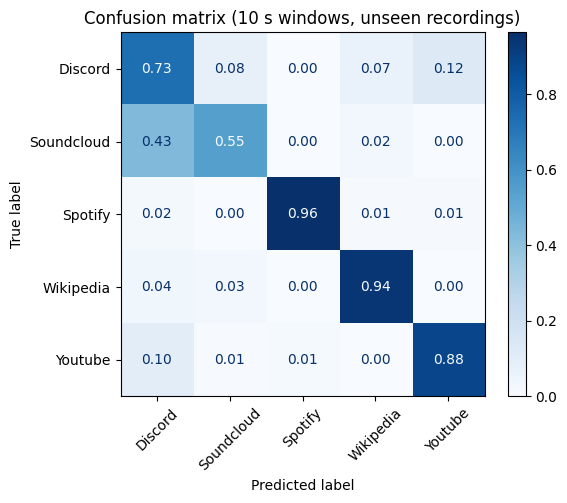

In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, normalize='true', values_format='.2f', cmap='Blues', xticks_rotation=45, ax=ax)
ax.set_title('Confusion matrix (10 s windows, unseen recordings)')
plt.tight_layout(); plt.show()


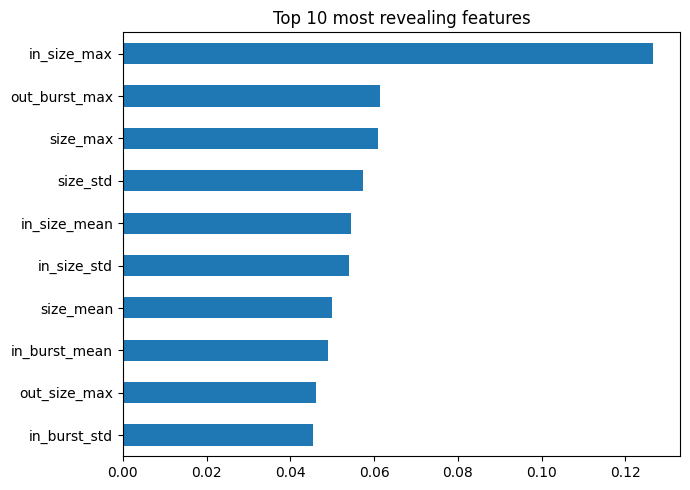

In [25]:
# Feature importance: which metadata leaks the most?
X = df_win.drop(columns=INFO_COLUMNS)
y = df_win['label']
final_model = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42).fit(X, y) # trained on ALL data

importance = pd.Series(final_model.feature_importances_, index=X.columns).sort_values()
importance.tail(10).plot.barh(figsize=(7, 5), title='Top 10 most revealing features')
plt.tight_layout(); plt.show()


PACKAGE SIZE LEAKS THE MOST! PADDING

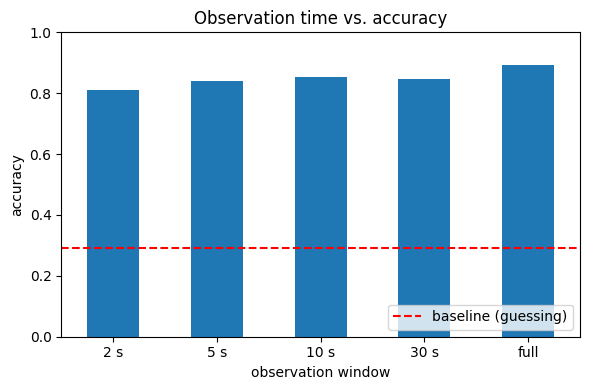

{'2 s': 0.8117088607594937, '5 s': 0.8395209580838323, '10 s': 0.8538899430740038, '30 s': 0.8465116279069768, 'full': 0.8918918918918919}


In [27]:
# How long does the attacker need to watch?
results = {}
for w in [2, 5, 10, 30]:
    yt, yp = evaluate(build_dataset(window=w))
    results[f'{w} s'] = accuracy_score(yt, yp)
results['full'] = accuracy_score(yf_true, yf_pred)

ax = pd.Series(results).plot.bar(rot=0, ylim=(0, 1), figsize=(6, 4), title='Observation time vs. accuracy')
ax.axhline(baseline, color='red', ls='--', label='baseline (guessing)')
ax.set_xlabel('observation window'); ax.set_ylabel('accuracy'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()
print(results)

2 seconds i even enough to guess!!

Done with the graphs 🎉

### C) DEPLOYMENT PART

Generated with AI code

In [28]:
import joblib, sklearn

# Bundle the model with the settings the live demo must reuse
bundle = {
    'model':       final_model,
    'features':    list(X.columns),   # exact column order the model expects
    'window':      WINDOW,
    'min_packets': MIN_PACKETS,
}
joblib.dump(bundle, '/content/drive/MyDrive/Computer_Security_Project/traffic_model.joblib')

print("Saved. scikit-learn version:", sklearn.__version__)

Saved. scikit-learn version: 1.6.1
